# ДЗ3

1. Для изображения `sar_3.jpg` найти наиболее протяжённый участок (выделить линии при помощи преобразования Хафа).
2. Для изображения `sar_3.jpg` провести исследование алгоритмов бинаризации, выделить участок дорожной полосы.

# Пункт 1. Самый протяжённый участок (преобразование Хафа)

In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

In [2]:
roi = (slice(90, 170), slice(30, 150))

In [3]:
gray_image = cv2.imread('sar_3.jpg', cv2.IMREAD_GRAYSCALE)

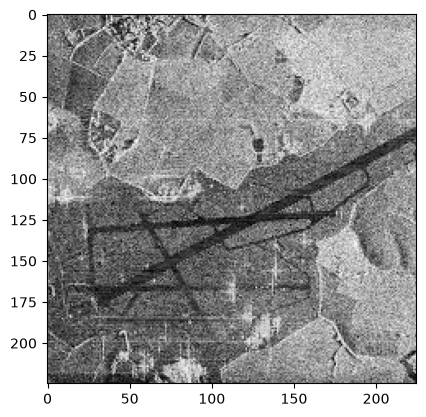

In [4]:
plt.imshow(gray_image, cmap='gray')

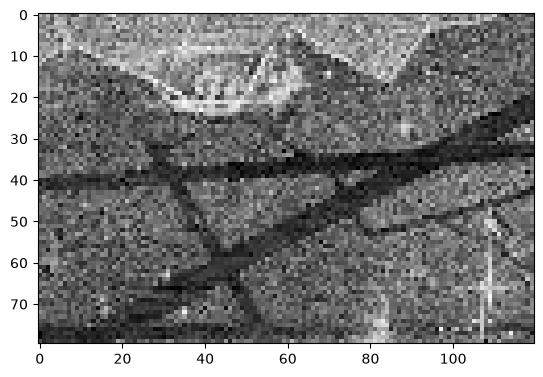

In [5]:
plt.imshow(gray_image[roi], cmap='gray')

In [6]:
gray_hist = cv2.calcHist([gray_image], [0], None, [256], (0, 256))

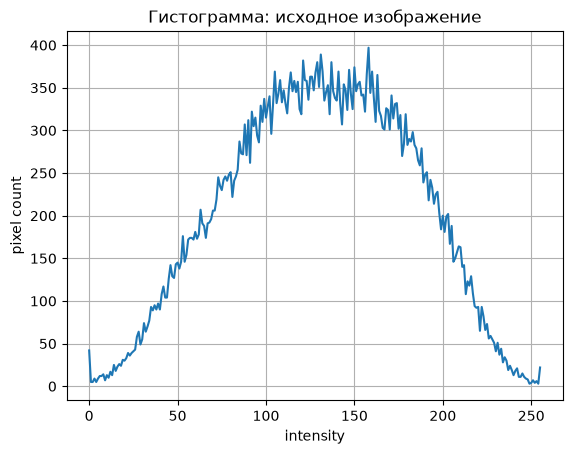

In [7]:
plt.plot(gray_hist)
plt.title("Гистограмма: исходное изображение")
plt.xlabel("intensity")
plt.ylabel("pixel count")
plt.grid()
plt.show()

In [8]:
filtered_image = cv2.medianBlur(gray_image, 7)
filtered_hist = cv2.calcHist([filtered_image], [0], None, [256], (0, 256))

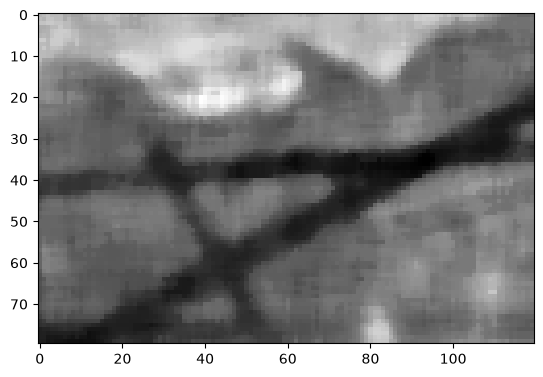

In [9]:
plt.imshow(filtered_image[roi], cmap='gray')

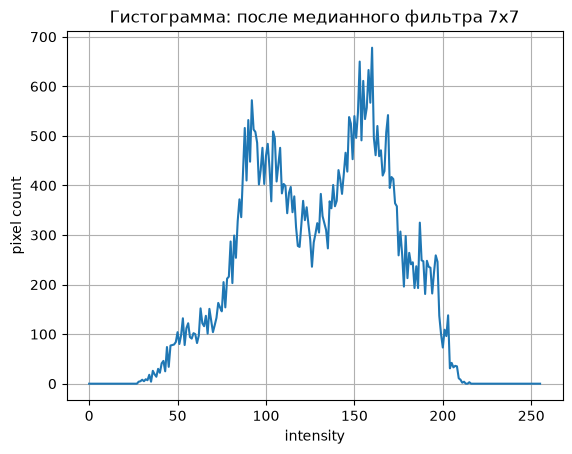

In [10]:
plt.plot(filtered_hist)
plt.title("Гистограмма: после медианного фильтра 7x7")
plt.xlabel("intensity")
plt.ylabel("pixel count")
plt.grid()
plt.show()

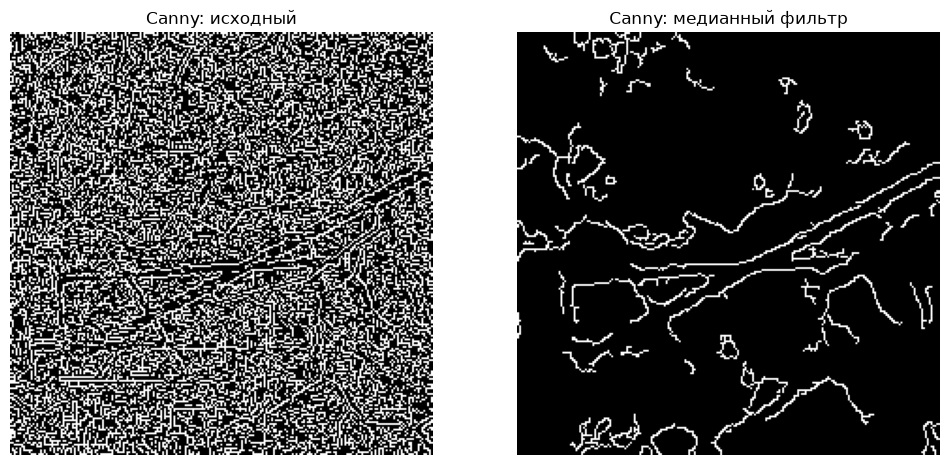

In [11]:
edges_raw = cv2.Canny(gray_image, 70, 150)
edges = cv2.Canny(filtered_image, 70, 150)

_, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(edges_raw, cmap='gray'); axes[0].set_title('Canny: исходный')
axes[1].imshow(edges, cmap='gray');     axes[1].set_title('Canny: медианный фильтр')
for ax in axes: ax.axis('off')
plt.show()

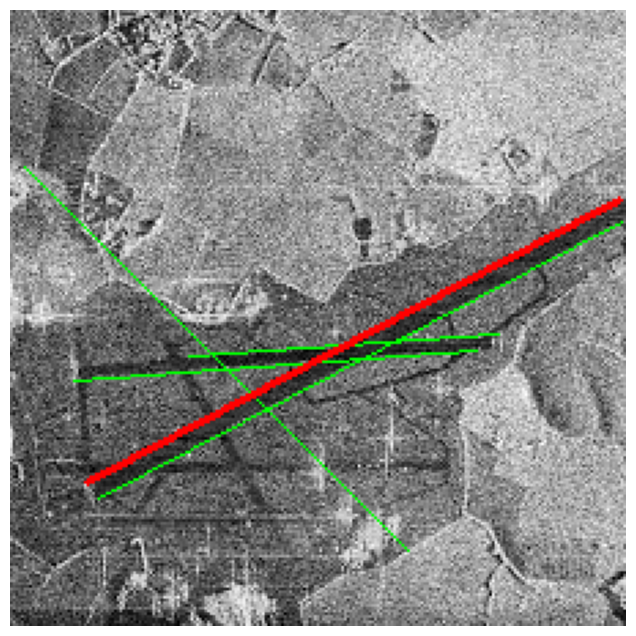

найдено отрезков: 5, самая длинная: 220 пикселей


In [12]:
lines = cv2.HoughLinesP(edges, 1, np.pi / 180, threshold=50,
                        minLineLength=30, maxLineGap=40)

result = cv2.cvtColor(gray_image, cv2.COLOR_GRAY2RGB)
longest, max_len = None, 0
for x1, y1, x2, y2 in lines.reshape(-1, 4):
    cv2.line(result, (x1, y1), (x2, y2), (0, 255, 0), 1)
    length = np.hypot(x2 - x1, y2 - y1)
    if length > max_len:
        max_len, longest = length, (x1, y1, x2, y2)

x1, y1, x2, y2 = longest
cv2.line(result, (x1, y1), (x2, y2), (255, 0, 0), 2)

plt.figure(figsize=(8, 8))
plt.imshow(result)
plt.axis('off')
plt.show()
print(f"найдено отрезков: {len(lines)}, самая длинная: {max_len:.0f} пикселей")

# Пункт 2. Исследование бинаризации

In [13]:
def iterative_threshold(img, eps=0.5):
    T = (int(img.min()) + int(img.max())) / 2
    while True:
        m1 = img[img <= T].mean()
        m2 = img[img > T].mean()
        T_new = (m1 + m2) / 2
        if abs(T_new - T) < eps:
            return T_new
        T = T_new

src = filtered_image
INV = cv2.THRESH_BINARY_INV

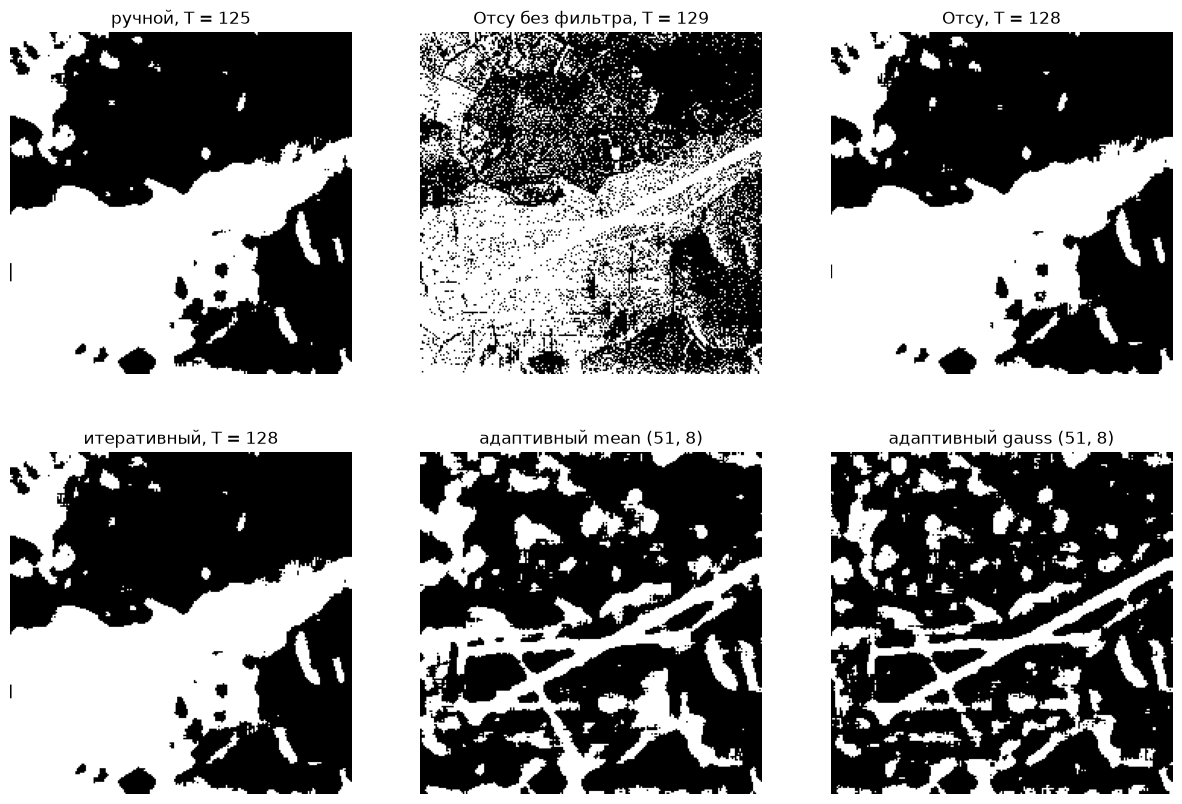

In [14]:
T_manual = 125
_, b_manual = cv2.threshold(src, T_manual, 255, INV)

T_otsu, b_otsu = cv2.threshold(src, 0, 255, INV + cv2.THRESH_OTSU)
T_otsu_raw, b_otsu_raw = cv2.threshold(gray_image, 0, 255, INV + cv2.THRESH_OTSU)

T_iter = iterative_threshold(src)
_, b_iter = cv2.threshold(src, T_iter, 255, INV)

b_mean  = cv2.adaptiveThreshold(src, 255, cv2.ADAPTIVE_THRESH_MEAN_C,     INV, 51, 8)
b_gauss = cv2.adaptiveThreshold(src, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, INV, 51, 8)

results = [
    (b_manual,   f'ручной, T = {T_manual}'),
    (b_otsu_raw, f'Отсу без фильтра, T = {T_otsu_raw:.0f}'),
    (b_otsu,     f'Отсу, T = {T_otsu:.0f}'),
    (b_iter,     f'итеративный, T = {T_iter:.0f}'),
    (b_mean,     'адаптивный mean (51, 8)'),
    (b_gauss,    'адаптивный gauss (51, 8)'),
]
_, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax, (img, title) in zip(axes.ravel(), results):
    ax.imshow(img, cmap='gray'); ax.set_title(title); ax.axis('off')
plt.show()

## Выделение полосы

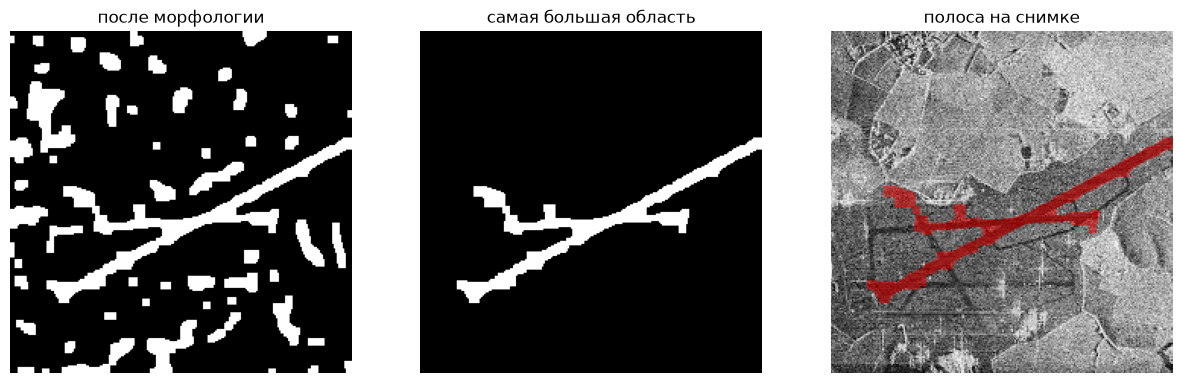

In [15]:
chosen = b_gauss

kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (5, 5))
opened = cv2.morphologyEx(chosen, cv2.MORPH_OPEN,  kernel)
closed = cv2.morphologyEx(opened, cv2.MORPH_CLOSE, kernel)

_, labels, stats, _ = cv2.connectedComponentsWithStats(closed)
biggest = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
road = (labels == biggest).astype(np.uint8) * 255

overlay = cv2.cvtColor(gray_image, cv2.COLOR_GRAY2RGB)
overlay[road > 0] = (0.5 * overlay[road > 0] + 0.5 * np.array([255, 0, 0])).astype(np.uint8)

_, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (img, title) in zip(axes, [(closed, 'после морфологии'), (road, 'самая большая область'), (overlay, 'полоса на снимке')]):
    ax.imshow(img, cmap='gray'); ax.set_title(title); ax.axis('off')
plt.show()